In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "ChargingRecords_Cleaned.csv"
)

df = pd.read_csv(DATA_PATH)

print("CLEANED DATA LOADED SUCCESSFULLY")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

CLEANED DATA LOADED SUCCESSFULLY
Dataset shape: (72826, 21)

Columns:
['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand', 'StartHour', 'StartMonth', 'StartWeekday', 'StartDate', 'DurationFromTimestamps', 'DurationDifference', 'DurationMismatch', 'DurationQuality']


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,...,Duration,Demand,StartHour,StartMonth,StartWeekday,StartDate,DurationFromTimestamps,DurationDifference,DurationMismatch,DurationQuality
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:02,...,185,20.36,20,9,Thursday,2022-09-15,185.183333,-0.183333,0,Match
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:05,...,90,10.19,20,9,Wednesday,2022-09-14,89.983333,0.016667,0,Match
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:30,...,60,6.78,18,9,Wednesday,2022-09-14,59.983333,0.016667,0,Match
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:51,...,344,37.65,18,9,Thursday,2022-09-29,343.850000,0.150000,0,Match
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:15,...,300,33.81,19,9,Sunday,2022-09-25,299.983333,0.016667,0,Match


In [2]:

print("DATA TYPES AND NON-NULL COUNTS")
df.info()

print("\nNUMERICAL SUMMARY")
display(df.describe().T)

print("\nMISSING VALUES")
display(
    df.isna().sum()
    .sort_values(ascending=False)
    .to_frame("MissingCount")
)

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.DataFrame'>
RangeIndex: 72826 entries, 0 to 72825
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   UserID                  72826 non-null  int64  
 1   ChargerID               72826 non-null  int64  
 2   ChargerCompany          72826 non-null  int64  
 3   Location                72826 non-null  str    
 4   ChargerType             72826 non-null  int64  
 5   StartDay                72826 non-null  str    
 6   StartTime               72826 non-null  str    
 7   EndDay                  72826 non-null  str    
 8   EndTime                 72826 non-null  str    
 9   StartDatetime           72826 non-null  str    
 10  EndDatetime             72826 non-null  str    
 11  Duration                72826 non-null  int64  
 12  Demand                  72826 non-null  float64
 13  StartHour               72826 non-null  int64  
 14  StartMonth        

,count,mean,std,min,25%,50%,75%,max
UserID,72826.0,337.978208,553.828304,0.000000,0.000000,61.000000,407.000000,2501.000000
ChargerID,72826.0,525.319172,569.513697,1.000000,107.000000,300.000000,738.000000,2671.000000
ChargerCompany,72826.0,0.627647,0.483435,0.000000,0.000000,1.000000,1.000000,1.000000
ChargerType,72826.0,0.205009,0.403711,0.000000,0.000000,0.000000,0.000000,1.000000
Duration,72826.0,151.222105,146.416111,0.000000,40.000000,112.000000,202.000000,1573.000000
Demand,72826.0,17.440366,13.490614,0.010000,7.530000,14.100000,23.200000,97.000000
StartHour,72826.0,14.610922,5.065620,0.000000,11.000000,16.000000,19.000000,23.000000
StartMonth,72826.0,6.244116,3.256757,1.000000,4.000000,6.000000,9.000000,12.000000
DurationFromTimestamps,72826.0,155.531298,159.158639,0.000000,40.583333,114.041667,203.979167,4717.033333
DurationDifference,72826.0,-4.309193,60.619169,-4320.033333,-0.300000,-0.033333,0.200000,870.266667



MISSING VALUES


,MissingCount
UserID,0
ChargerID,0
ChargerCompany,0
Location,0
ChargerType,0
StartDay,0
StartTime,0
EndDay,0
EndTime,0
StartDatetime,0


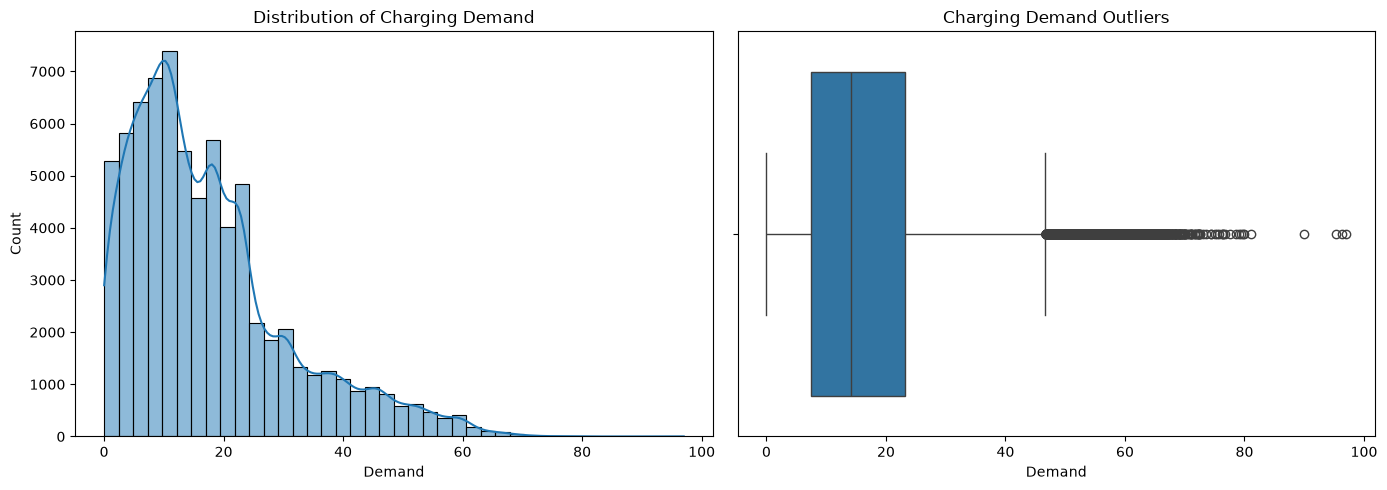

Demand statistics:


count    72826.000000
mean        17.440366
std         13.490614
min          0.010000
25%          7.530000
50%         14.100000
75%         23.200000
max         97.000000
Name: Demand, dtype: float64

In [3]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="Demand",
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Charging Demand")

sns.boxplot(
    data=df,
    x="Demand",
    ax=axes[1]
)
axes[1].set_title("Charging Demand Outliers")

plt.tight_layout()
plt.show()

print("Demand statistics:")
display(df["Demand"].describe())

,count,mean,median
Location,,,
accommodation,187,29.06,28.73
bus garage,29,28.59,29.91
camping,1630,25.53,23.53
apartment,14036,18.74,14.40
public area,14076,17.90,14.53
restaurant,2222,17.81,13.80
public institution,7023,17.40,14.42
resort,8854,17.28,14.00
public parking lot,3394,17.19,16.00


,count,mean,median
ChargerType,,,
0,57896,17.05,13.10
1,14930,18.95,17.15


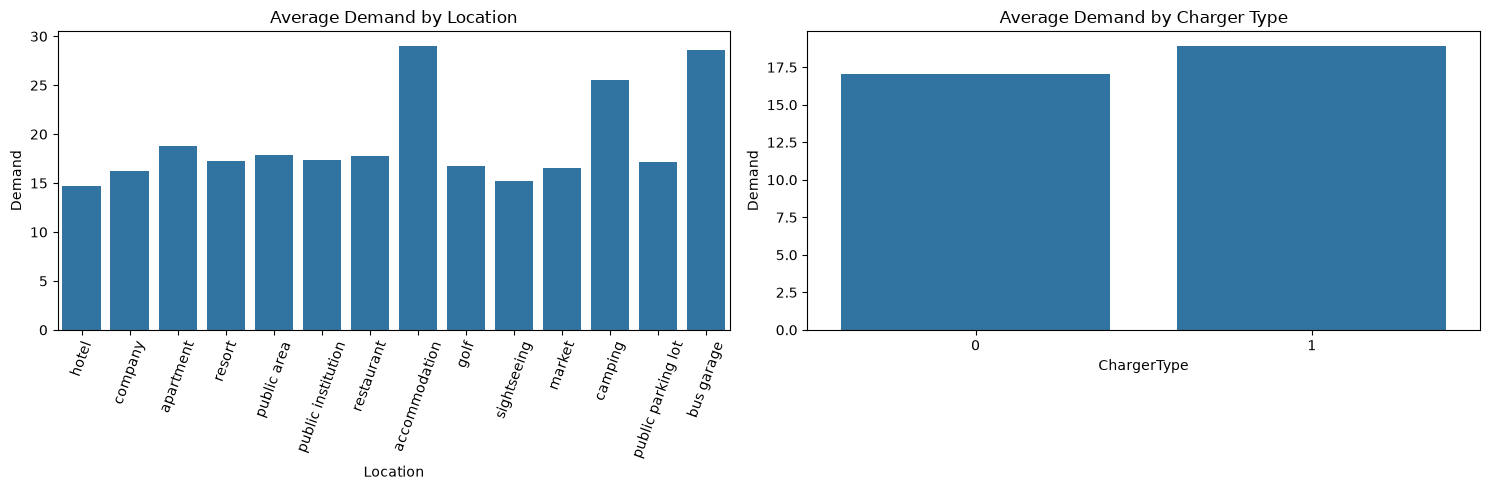

In [4]:

# Average demand by location
location_demand = (
    df.groupby("Location")["Demand"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
    .round(2)
)

display(location_demand)

# Average demand by charger type
charger_demand = (
    df.groupby("ChargerType")["Demand"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(charger_demand)

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=df,
    x="Location",
    y="Demand",
    estimator="mean",
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Average Demand by Location")
axes[0].tick_params(axis="x", rotation=70)

sns.barplot(
    data=df,
    x="ChargerType",
    y="Demand",
    estimator="mean",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Average Demand by Charger Type")

plt.tight_layout()
plt.show()

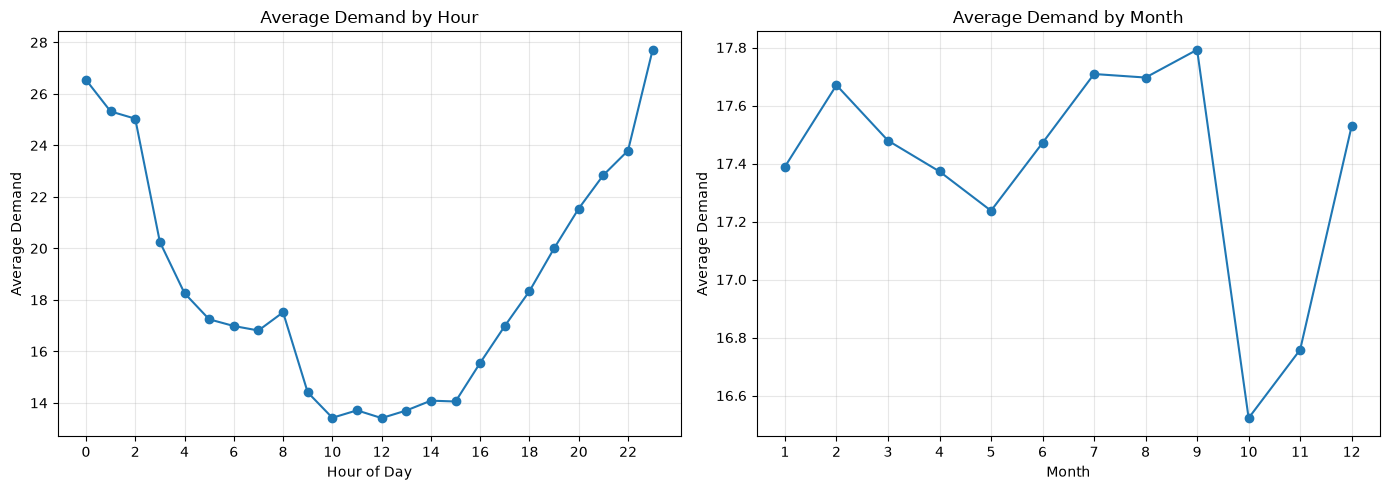

Highest-average-demand hour: 23
Highest-average-demand month: 9


In [5]:

# Parse the session start timestamp
df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"], errors="coerce"
)

df["StartHour"] = df["StartDatetime"].dt.hour
df["StartMonth"] = df["StartDatetime"].dt.month

# Average demand by hour
hourly_demand = (
    df.groupby("StartHour")["Demand"]
    .mean()
    .reindex(range(24))
)

# Average demand by month
monthly_demand = (
    df.groupby("StartMonth")["Demand"]
    .mean()
    .reindex(range(1, 13))
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

hourly_demand.plot(marker="o", ax=axes[0])
axes[0].set_title("Average Demand by Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Average Demand")
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(alpha=0.3)

monthly_demand.plot(marker="o", ax=axes[1])
axes[1].set_title("Average Demand by Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Average Demand")
axes[1].set_xticks(range(1, 13))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Highest-average-demand hour:", int(hourly_demand.idxmax()))
print("Highest-average-demand month:", int(monthly_demand.idxmax()))

DEMAND ANALYSIS BY DAY OF THE WEEK


,count,mean,median
StartWeekday,,,
Monday,10321,17.35,14.05
Tuesday,10644,17.10,13.80
Wednesday,10878,17.53,14.13
Thursday,11050,17.62,14.38
Friday,11008,17.31,13.96
Saturday,9939,17.41,14.02
Sunday,8986,17.81,14.45


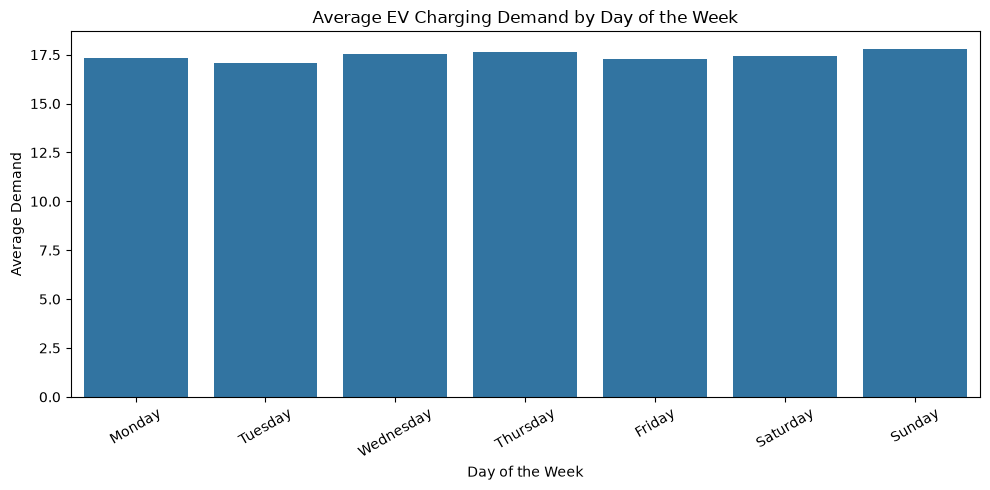

Highest-demand day: Sunday
Lowest-demand day: Tuesday


In [6]:

# Average demand by day of the week
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

df["StartWeekday"] = df["StartDatetime"].dt.day_name()

weekday_demand = (
    df.groupby("StartWeekday")["Demand"]
    .agg(["count", "mean", "median"])
    .reindex(weekday_order)
    .round(2)
)

print("DEMAND ANALYSIS BY DAY OF THE WEEK")
display(weekday_demand)

# Visualize average demand by weekday
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x="StartWeekday",
    y="Demand",
    order=weekday_order,
    estimator="mean",
    errorbar=None
)
plt.title("Average EV Charging Demand by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Demand")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Highest-demand day:", weekday_demand["mean"].idxmax())
print("Lowest-demand day:", weekday_demand["mean"].idxmin())

WEEKDAY VS WEEKEND DEMAND


,count,mean,median,std
DayType,,,,
Weekday,53901,17.38,14.06,13.45
Weekend,18925,17.60,14.26,13.61


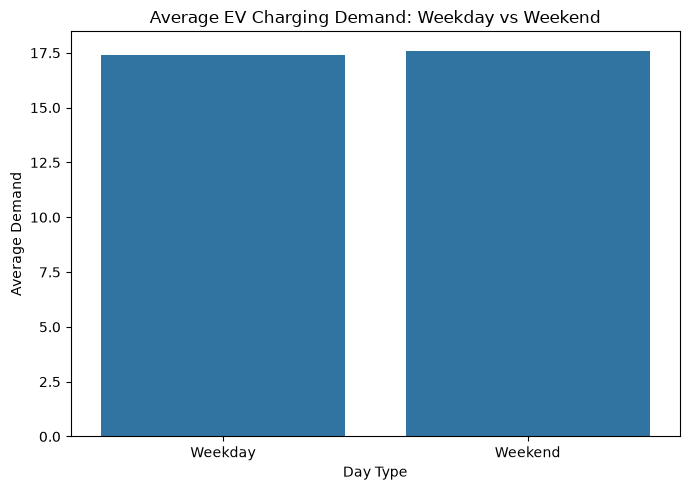

In [7]:

# Separate weekdays and weekends
df["DayType"] = np.where(
    df["StartDatetime"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

daytype_analysis = (
    df.groupby("DayType")["Demand"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print("WEEKDAY VS WEEKEND DEMAND")
display(daytype_analysis)

# Visualize the comparison
plt.figure(figsize=(7, 5))
sns.barplot(
    data=df,
    x="DayType",
    y="Demand",
    estimator="mean",
    errorbar=None
)
plt.title("Average EV Charging Demand: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Demand")
plt.tight_layout()
plt.show()

DEMAND ANALYSIS BY CHARGER COMPANY


,count,mean,median,std
ChargerCompany,,,,
1,45709,17.89,14.65,14.01
0,27117,16.69,13.29,12.54


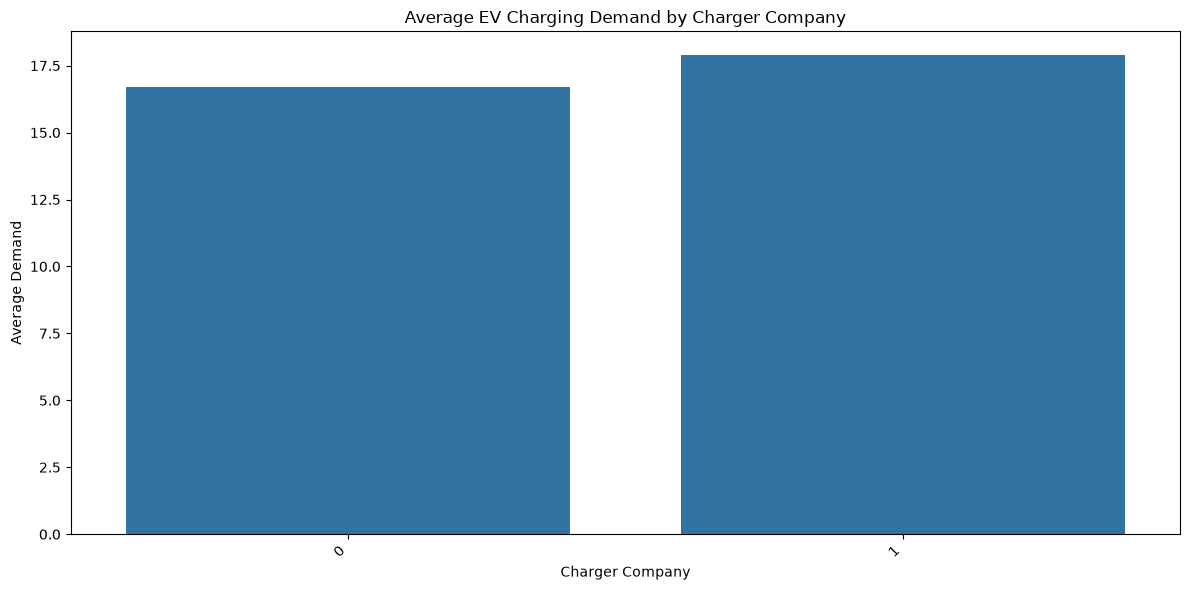

In [8]:

# Demand by charger company
company_demand = (
    df.groupby("ChargerCompany")["Demand"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
    .round(2)
)

print("DEMAND ANALYSIS BY CHARGER COMPANY")
display(company_demand)

# Visualize average demand by company
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x="ChargerCompany",
    y="Demand",
    estimator="mean",
    errorbar=None
)
plt.title("Average EV Charging Demand by Charger Company")
plt.xlabel("Charger Company")
plt.ylabel("Average Demand")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

DEMAND ANALYSIS BY CHARGER TYPE


,count,mean,median,std
ChargerType,,,,
1,14930,18.95,17.15,12.23
0,57896,17.05,13.10,13.77


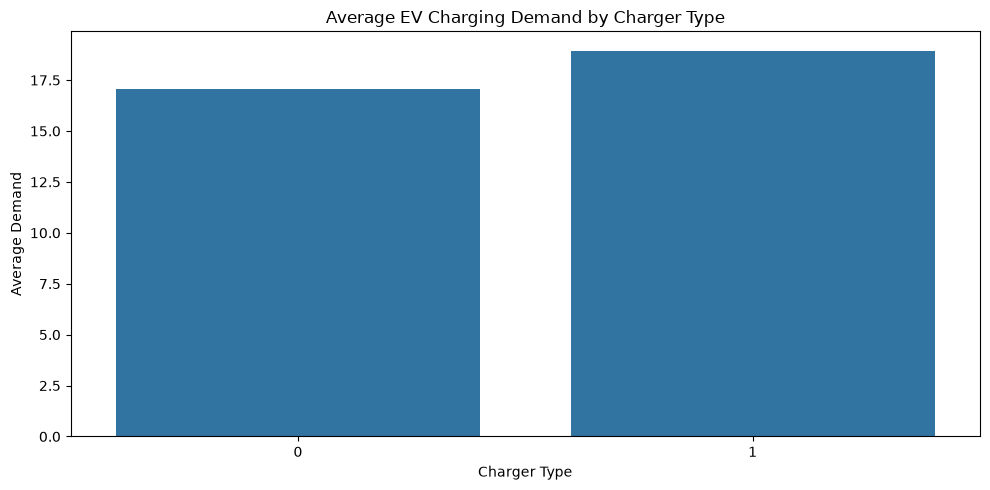

In [9]:

# Demand analysis by charger type
charger_type_demand = (
    df.groupby("ChargerType")["Demand"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
    .round(2)
)

print("DEMAND ANALYSIS BY CHARGER TYPE")
display(charger_type_demand)

# Visualize average demand by charger type
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x="ChargerType",
    y="Demand",
    estimator="mean",
    errorbar=None
)
plt.title("Average EV Charging Demand by Charger Type")
plt.xlabel("Charger Type")
plt.ylabel("Average Demand")
plt.tight_layout()
plt.show()

CORRELATION WITH DEMAND


,Demand
Demand,1.000
Duration,0.657
DurationFromTimestamps,0.604
StartHour,0.127
ChargerType,0.057
ChargerCompany,0.043
DurationDifference,0.000
StartMonth,-0.005


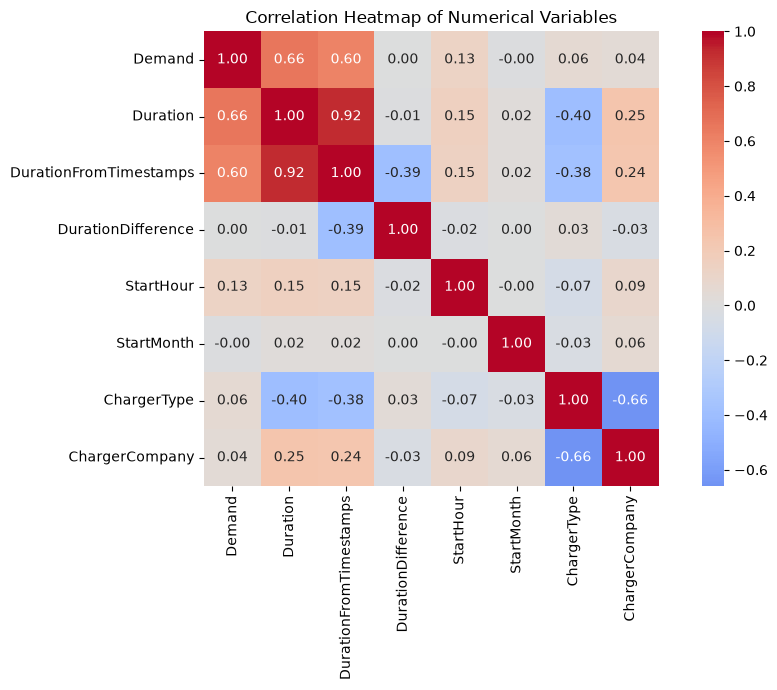

In [10]:

# Select numerical columns for correlation analysis
numeric_cols = [
    "Demand",
    "Duration",
    "DurationFromTimestamps",
    "DurationDifference",
    "StartHour",
    "StartMonth",
    "ChargerType",
    "ChargerCompany",
]

numeric_cols = [col for col in numeric_cols if col in df.columns]

correlation_matrix = df[numeric_cols].corr(numeric_only=True)

print("CORRELATION WITH DEMAND")
display(
    correlation_matrix[["Demand"]]
    .sort_values("Demand", ascending=False)
    .round(3)
)

# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    square=True
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

In [11]:

# Summary of key EDA findings

print("=" * 55)
print("EV CHARGING DEMAND — EDA SUMMARY")
print("=" * 55)

print(f"Total cleaned records: {len(df):,}")
print(f"Average demand: {df['Demand'].mean():.2f}")
print(f"Median demand: {df['Demand'].median():.2f}")
print(f"Minimum demand: {df['Demand'].min():.2f}")
print(f"Maximum demand: {df['Demand'].max():.2f}")

print("\nTEMPORAL PATTERNS")
print(f"Highest-demand hour: {hourly_demand.idxmax()}:00")
print(f"Highest-demand month: {monthly_demand.idxmax()}")
print(f"Highest-demand weekday: {weekday_demand['mean'].idxmax()}")
print(f"Lowest-demand weekday: {weekday_demand['mean'].idxmin()}")

print("\nGROUP COMPARISONS")
print(f"Weekday average demand: {df.loc[df['DayType'] == 'Weekday', 'Demand'].mean():.2f}")
print(f"Weekend average demand: {df.loc[df['DayType'] == 'Weekend', 'Demand'].mean():.2f}")

print("\nDATA QUALITY")
print(f"Duration mismatch records: {int(df['DurationMismatch'].sum()):,}")
print(f"Duration mismatch rate: {df['DurationMismatch'].mean() * 100:.2f}%")

print("\nEDA SUMMARY COMPLETED")

EV CHARGING DEMAND — EDA SUMMARY
Total cleaned records: 72,826
Average demand: 17.44
Median demand: 14.10
Minimum demand: 0.01
Maximum demand: 97.00

TEMPORAL PATTERNS
Highest-demand hour: 23:00
Highest-demand month: 9
Highest-demand weekday: Sunday
Lowest-demand weekday: Tuesday

GROUP COMPARISONS
Weekday average demand: 17.38
Weekend average demand: 17.60

DATA QUALITY
Duration mismatch records: 4,263
Duration mismatch rate: 5.85%

EDA SUMMARY COMPLETED
